# ¿Cuánto infla las métricas partir por imagen en vez de por objeto?

Justifica la decisión de partir por **objeto físico** (`docs/estrategia_solucion.md`, decisión 2). Se entrena el **mismo**
Random Forest sobre las mismas características de color con dos tipos de partición 80/20 y se comparan:

* **aleatoria por imagen** (estratificada por especie × clase), y
* **agrupada por objeto** (`StratifiedGroupKFold`, ningún grupo en ambos lados).

Además se mide el **mecanismo** de la fuga: qué fracción de las imágenes de prueba tiene un casi-duplicado (hash perceptual a
distancia ≤ 5, de la misma especie y fuente) en el entrenamiento.

**Reglas:** solo se usan `train` y `val` de la partición fija; **el test no se toca**. Las 5 semillas varían la partición, no los datos.
Los grupos son una **aproximación** (tiempo, hash y contador): una partición "agrupada" puede conservar fuga residual, así que
la diferencia medida es una **cota inferior** de la inflación real.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedShuffleSplit

REPO = Path.cwd().parent if Path.cwd().name == "04_modelado" else Path.cwd()
sys.path.insert(0, str(REPO / "src"))
import features as ft
import splits

PROC = REPO / "data" / "processed"
FIG = REPO / "04_modelado" / "figuras"
FIG.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["savefig.bbox"] = "tight"
SEED_BASE = 0

part = pd.read_pickle(PROC / "partition.pkl")
dev = part[part["split"].isin(["train", "val"])].reset_index(drop=True)      # el test NO se usa
dev["strata"] = splits.make_strata(dev, ["species", "label_weak"])
thumbs = np.load(PROC / "thumbs64.npy", mmap_mode="r")
X = ft.color_features(np.asarray(thumbs[dev["row"].to_numpy()]), "full")
hashes = np.load(PROC / "hashes16.npy")[dev["row"].to_numpy()]
y = dev["label_weak"].to_numpy()
print(f"imágenes de desarrollo (train + val): {len(dev):,} | grupos: {dev['group'].nunique():,} | características: {X.shape[1]}")

imágenes de desarrollo (train + val): 15,808 | grupos: 2,720 | características: 136


In [2]:
def casi_duplicados(idx_tr, idx_te, max_dist=5, chunk=512):
    """Fracción de imágenes de prueba con algún casi-duplicado (misma especie y fuente) en entrenamiento."""
    celda = dev["species"] + "|" + dev["source"]
    hit = 0
    for c in celda.unique():
        a = idx_tr[celda.iloc[idx_tr].to_numpy() == c]
        b = idx_te[celda.iloc[idx_te].to_numpy() == c]
        if len(a) == 0 or len(b) == 0:
            continue
        for s in range(0, len(b), chunk):
            d = np.bitwise_count(hashes[b[s:s + chunk]][:, None, :] ^ hashes[a][None, :, :]).sum(axis=2)
            hit += int((d.min(axis=1) <= max_dist).sum())
    return hit / len(idx_te)


def correr(tipo, semilla):
    if tipo == "aleatoria":
        tr, te = next(StratifiedShuffleSplit(1, test_size=0.2, random_state=semilla).split(X, dev["strata"]))
    else:
        a, b = splits.grouped_split(dev.reset_index(), label_col="label_weak", test_size=0.2, seed=semilla, strata_col="strata")
        tr, te = a["index"].to_numpy(), b["index"].to_numpy()
    rf = RandomForestClassifier(200, random_state=semilla, n_jobs=4, class_weight="balanced").fit(X[tr], y[tr])
    pred = rf.predict(X[te])
    fila = {"partición": tipo, "semilla": semilla, "n_test": len(te), "F1_macro": f1_score(y[te], pred, average="macro"),
            "exactitud": accuracy_score(y[te], pred)}
    if semilla == SEED_BASE:
        fila["casi_duplicados_test_en_train"] = casi_duplicados(tr, te)
    return fila


filas = [correr(t, s) for s in range(SEED_BASE, SEED_BASE + 5) for t in ("aleatoria", "agrupada")]
res = pd.DataFrame(filas)
res.round(4)

,partición,semilla,n_test,F1_macro,exactitud,casi_duplicados_test_en_train
0,aleatoria,0,3162,0.9881,0.9889,0.4994
1,agrupada,0,3162,0.9666,0.9693,0.0000
2,aleatoria,1,3162,0.9854,0.9864,NaN
3,agrupada,1,3162,0.9525,0.9567,NaN
4,aleatoria,2,3162,0.9857,0.9867,NaN
5,agrupada,2,3162,0.9653,0.9681,NaN
6,aleatoria,3,3162,0.9871,0.9880,NaN
7,agrupada,3,3162,0.9622,0.9652,NaN
8,aleatoria,4,3162,0.9867,0.9877,NaN
9,agrupada,4,3162,0.9511,0.9554,NaN


In [3]:
resumen = res.groupby("partición").agg(F1_media=("F1_macro", "mean"), F1_de=("F1_macro", "std"),
                                       exactitud_media=("exactitud", "mean"), n_test=("n_test", "mean"),
                                       casi_dup=("casi_duplicados_test_en_train", "max")).round(4)
resumen

,F1_media,F1_de,exactitud_media,n_test,casi_dup
partición,,,,,
agrupada,0.9595,0.0073,0.9629,3162.0,0.0000
aleatoria,0.9866,0.0011,0.9875,3162.0,0.4994



**Lectura de los resultados** (media de 5 semillas, solo `train` y `val`).

* **Partir por imagen infla el F1 macro en unos 0.027:** 0.9866 con la partición aleatoria frente a 0.9595 con la agrupada por objeto.
  La partición agrupada además es más variable entre semillas (desviación 0.0073 frente a 0.0011), como cabe esperar cuando se
  reparten grupos grandes y no imágenes sueltas.
* **Mecanismo:** con la partición aleatoria, el **49.9 %** de las imágenes de prueba tiene un casi-duplicado (hash perceptual a
  distancia ≤ 5, misma especie y fuente) en el entrenamiento: el modelo "ya vio" la mitad de lo que se le evalúa.
* **Advertencia sobre el 0.0 % de la partición agrupada:** es **cero por construcción**, porque los grupos se formaron con ese
  mismo criterio de hash. No es evidencia independiente de que no haya fuga: lo es la diferencia de F1.
* **Cota inferior:** los grupos son una aproximación (tiempo, hash y contador) y pueden dejar fuga residual (rotaciones, recortes,
  imágenes aumentadas), así que 0.027 es una **cota inferior** de la inflación real. Las métricas de la partición agrupada
  siguen siendo optimistas.
* Aun con la partición agrupada, el F1 de ~0.96 en Kaggle **no demuestra que se aprenda calidad**: el fondo ya predice la clase
  (ver `02_comprension_datos/eda.ipynb` §7).


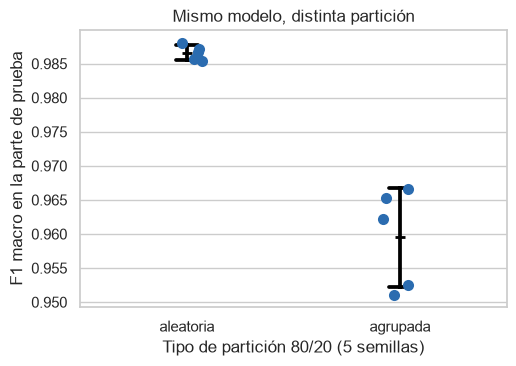

In [4]:
fig, ax = plt.subplots(figsize=(5.5, 3.6))
sns.stripplot(data=res, x="partición", y="F1_macro", color="#2B6CB0", size=8, ax=ax, jitter=0.08)
sns.pointplot(data=res, x="partición", y="F1_macro", color="black", errorbar="sd", markers="_", linestyles="", capsize=0.1, ax=ax)
ax.set_xlabel("Tipo de partición 80/20 (5 semillas)"); ax.set_ylabel("F1 macro en la parte de prueba")
ax.set_title("Mismo modelo, distinta partición")
fig.savefig(FIG / "fuga_particion.pdf")
plt.show()